In [1]:

!pip install pandas numpy matplotlib seaborn scikit-learn scipy


In [2]:

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
import re

uploaded = files.upload()

print("Fisiere incarcate:")
print(list(uploaded.keys()))


Saving GHSL_Prahova_2010_2025_CP2.csv to GHSL_Prahova_2010_2025_CP2.csv
Saving Eurostat_Prahova_2010_2025.csv to Eurostat_Prahova_2010_2025.csv
Fisiere incarcate:
['GHSL_Prahova_2010_2025_CP2.csv', 'Eurostat_Prahova_2010_2025.csv']


In [3]:

# Identificam fisierele incarcate
eurostat_file = next(
    f for f in uploaded if "eurostat" in f.lower()
)

ghsl_file = next(
    f for f in uploaded if "ghsl" in f.lower()
)

# Citim fisierele
eurostat_df = pd.read_csv(eurostat_file)
ghsl_df = pd.read_csv(ghsl_file)

print("Date Eurostat:")
display(eurostat_df.head())

print("Date GHSL:")
display(ghsl_df.head())

print("Dimensiune Eurostat:", eurostat_df.shape)
print("Dimensiune GHSL:", ghsl_df.shape)


Date Eurostat:


,LAU_CODE,UAT_Name,Pop_2010,Pop_2015,Pop_2020,Pop_2025,Area_km2_2010,Area_km2_2015,Area_km2_2020,Area_km2_2025
0,130534,Municipiul Ploiesti,227981,222461,225049,207886,58.28,58.26,58.255292,58.255292
1,131256,Municipiul Campina,37054,35662,36139,33674,24.23,24.23,24.225626,24.225625
2,130954,Oras Azuga,4903,4742,4649,4363,83.04,83.04,82.889541,82.889540
3,130981,Oras Baicoi,19637,19178,18721,17910,65.36,65.36,67.984752,67.984751
4,131069,Oras Boldesti-Scaeni,11484,11298,11552,11375,34.90,34.90,34.916430,34.916429


Date GHSL:


,name,An,Built_km2
0,Gorgota,2010,0.699497
1,Balta Doamnei,2010,0.506186
2,Olari,2010,0.341707
3,GherghițA,2010,0.396108
4,șIrna,2010,0.578653


Dimensiune Eurostat: (104, 10)
Dimensiune GHSL: (416, 3)


In [4]:

# Normalizam numele UAT-urilor
def normalize_name(name):
    name = str(name).lower().strip()

    name = unicodedata.normalize(
        "NFKD", name
    ).encode("ascii", "ignore").decode("ascii")

    name = re.sub(
        r"^(municipiul|orasul|oras|comuna)\s+", "", name
    )

    name = re.sub(r"[^a-z0-9]", "", name)

    return name


# Pregatim cheia de asociere
eurostat_df["name_key"] = eurostat_df["UAT_Name"].apply(
    normalize_name
)

ghsl_df["name_key"] = ghsl_df["name"].apply(
    normalize_name
)

# Transformam anii in numere
ghsl_df["An"] = pd.to_numeric(
    ghsl_df["An"], errors="coerce"
)

ghsl_df["Built_km2"] = pd.to_numeric(
    ghsl_df["Built_km2"], errors="coerce"
)

# Transformam GHSL din format lung in format tabelar
ghsl_wide = ghsl_df.pivot_table(
    index="name_key",
    columns="An",
    values="Built_km2",
    aggfunc="mean"
).reset_index()

ghsl_wide.columns.name = None

ghsl_wide = ghsl_wide.rename(columns={
    2010: "Built_2010",
    2015: "Built_2015",
    2020: "Built_2020",
    2025: "Built_2025"
})

# Unim Eurostat cu GHSL
df = eurostat_df.merge(
    ghsl_wide,
    on="name_key",
    how="inner"
)

print("Numar UAT-uri asociate:", len(df))
print("UAT-uri neasociate:",
      len(eurostat_df) - len(df))

display(df.head())


Numar UAT-uri asociate: 104
UAT-uri neasociate: 0


,LAU_CODE,UAT_Name,Pop_2010,Pop_2015,Pop_2020,Pop_2025,Area_km2_2010,Area_km2_2015,Area_km2_2020,Area_km2_2025,name_key,Built_2010,Built_2015,Built_2020,Built_2025
0,130534,Municipiul Ploiesti,227981,222461,225049,207886,58.28,58.26,58.255292,58.255292,ploiesti,9.673366,10.087903,10.298875,10.449175
1,131256,Municipiul Campina,37054,35662,36139,33674,24.23,24.23,24.225626,24.225625,campina,2.366006,2.478764,2.532016,2.573103
2,130954,Oras Azuga,4903,4742,4649,4363,83.04,83.04,82.889541,82.889540,azuga,0.323192,0.352701,0.401827,0.414167
3,130981,Oras Baicoi,19637,19178,18721,17910,65.36,65.36,67.984752,67.984751,baicoi,2.015171,2.254734,2.401637,2.576728
4,131069,Oras Boldesti-Scaeni,11484,11298,11552,11375,34.90,34.90,34.916430,34.916429,boldestiscaeni,1.211758,1.332254,1.461671,1.530049


Statistici descriptive:


,count,mean,std,min,25%,50%,75%,max
Pop_2010,104.0,7833.548077,22322.723687,620.000000,2431.500000,4888.000000,7082.250000,227981.000000
Pop_2025,104.0,7223.500000,20381.782008,457.000000,2134.500000,4360.000000,6462.750000,207886.000000
Built_2010,104.0,0.717969,0.987277,0.110601,0.323743,0.533541,0.791970,9.673366
Built_2025,104.0,0.862934,1.090739,0.119550,0.367458,0.669551,0.941169,10.449175


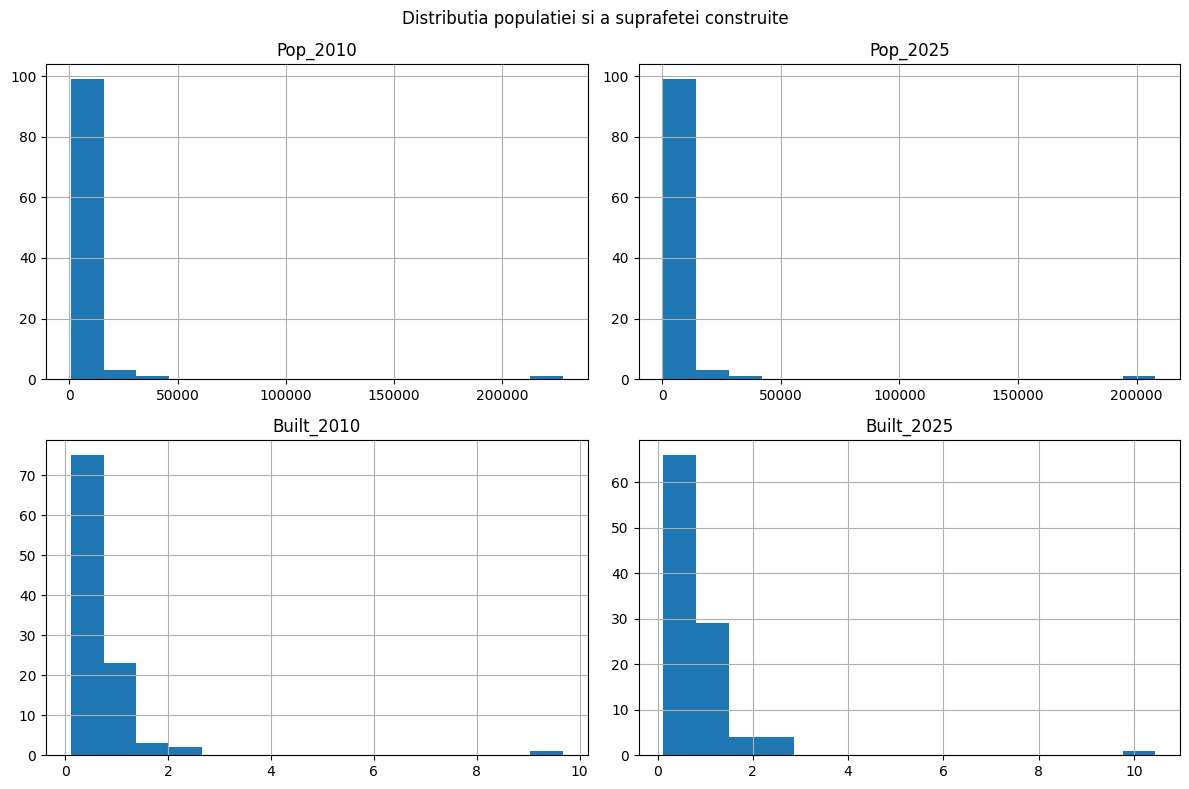

In [5]:

# Statistici descriptive
coloane = [
    "Pop_2010",
    "Pop_2025",
    "Built_2010",
    "Built_2025"
]

print("Statistici descriptive:")
display(df[coloane].describe().T)

# Grafice de distributie
df[coloane].hist(
    figsize=(12, 8),
    bins=15
)

plt.suptitle("Distributia populatiei si a suprafetei construite")
plt.tight_layout()
plt.show()


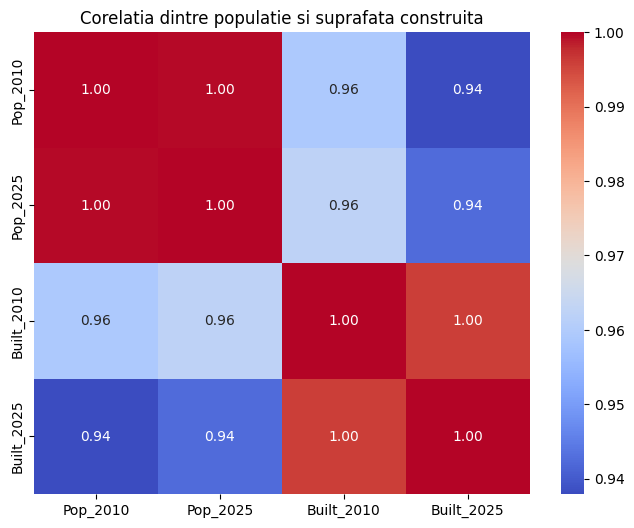

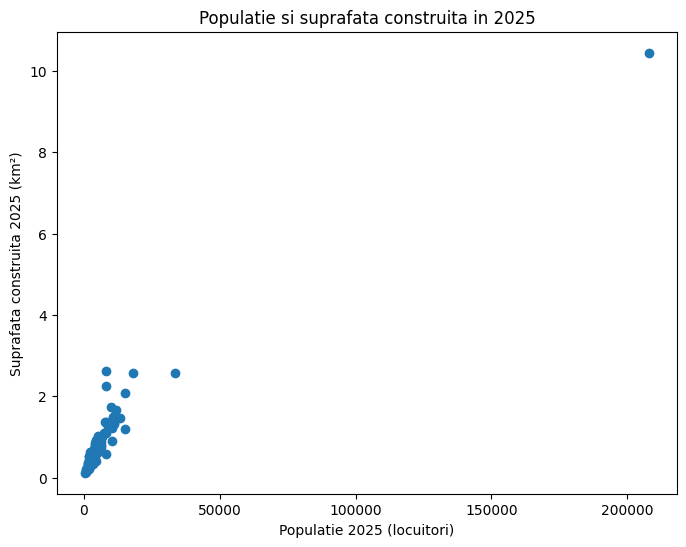

In [6]:

# Corelatia dintre variabile
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[coloane].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Corelatia dintre populatie si suprafata construita")
plt.show()

# Grafic populatie - suprafata construita
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Pop_2025"],
    df["Built_2025"]
)

plt.xlabel("Populatie 2025 (locuitori)")
plt.ylabel("Suprafata construita 2025 (km²)")
plt.title("Populatie si suprafata construita in 2025")

plt.show()


In [7]:

# Selectam cele 8 caracteristici
features = [
    "Pop_2010",
    "Pop_2015",
    "Pop_2020",
    "Pop_2025",
    "Built_2010",
    "Built_2015",
    "Built_2020",
    "Built_2025"
]

# Construim matricea X
X = df[features].replace(
    [np.inf, -np.inf], np.nan
).dropna()

df_valid = df.loc[X.index].copy()

print("MATRICEA X")
print("Numar UAT-uri:", len(X))
print("Numar caracteristici:", len(features))

display(X.head())

print("Statistici descriptive:")
display(X.describe().T)

# Salvam matricea
X.to_csv("Matricea_X_CP2.csv", index=True)


MATRICEA X
Numar UAT-uri: 104
Numar caracteristici: 8


,Pop_2010,Pop_2015,Pop_2020,Pop_2025,Built_2010,Built_2015,Built_2020,Built_2025
0,227981,222461,225049,207886,9.673366,10.087903,10.298875,10.449175
1,37054,35662,36139,33674,2.366006,2.478764,2.532016,2.573103
2,4903,4742,4649,4363,0.323192,0.352701,0.401827,0.414167
3,19637,19178,18721,17910,2.015171,2.254734,2.401637,2.576728
4,11484,11298,11552,11375,1.211758,1.332254,1.461671,1.530049


Statistici descriptive:


,count,mean,std,min,25%,50%,75%,max
Pop_2010,104.0,7833.548077,22322.723687,620.000000,2431.500000,4888.000000,7082.250000,227981.000000
Pop_2015,104.0,7675.817308,21781.165616,539.000000,2364.500000,4759.500000,6975.750000,222461.000000
Pop_2020,104.0,7572.394231,22051.615014,482.000000,2232.750000,4535.000000,6632.750000,225049.000000
Pop_2025,104.0,7223.500000,20381.782008,457.000000,2134.500000,4360.000000,6462.750000,207886.000000
Built_2010,104.0,0.717969,0.987277,0.110601,0.323743,0.533541,0.791970,9.673366
Built_2015,104.0,0.781995,1.038009,0.115923,0.345806,0.596901,0.859610,10.087903
Built_2020,104.0,0.825524,1.066608,0.119548,0.362887,0.635785,0.896493,10.298875
Built_2025,104.0,0.862934,1.090739,0.119550,0.367458,0.669551,0.941169,10.449175


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Impartim datele
train_idx, test_idx = train_test_split(
    np.arange(len(X)),
    test_size=0.2,
    random_state=42
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

# Standardizam datele
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Aplicam PCA
pca = PCA()

pca.fit(X_train_scaled)

X_train_pca = pca.transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Alegem numarul de componente pentru minimum 80% varianta
varianta_cumulata = np.cumsum(
    pca.explained_variance_ratio_
)

k = np.argmax(varianta_cumulata >= 0.80) + 1

print("Numar componente PCA ales:", k)
print("Varianta explicata:", round(
    varianta_cumulata[k-1] * 100, 2
), "%")


Numar componente PCA ales: 1
Varianta explicata: 95.56 %


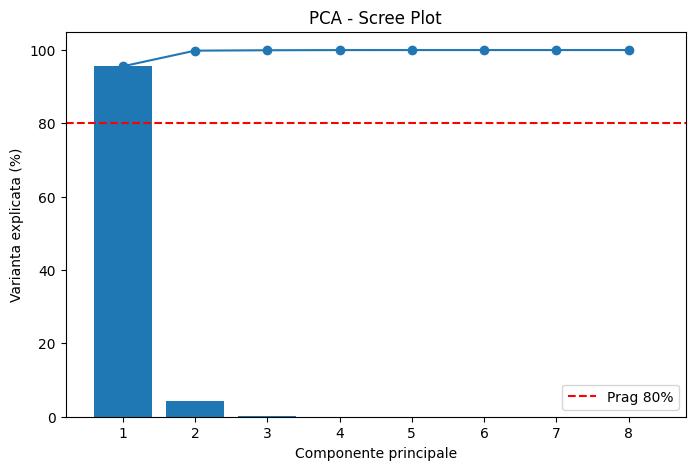

In [9]:

plt.figure(figsize=(8, 5))

plt.bar(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_ * 100
)

plt.plot(
    range(1, len(varianta_cumulata) + 1),
    varianta_cumulata * 100,
    marker="o"
)

plt.axhline(
    80,
    color="red",
    linestyle="--",
    label="Prag 80%"
)

plt.xlabel("Componente principale")
plt.ylabel("Varianta explicata (%)")
plt.title("PCA - Scree Plot")
plt.legend()
plt.show()


Contributia caracteristicilor la componentele PCA:


,PC1,PC2
Pop_2010,0.352,-0.385
Pop_2015,0.354,-0.356
Pop_2020,0.353,-0.362
Pop_2025,0.355,-0.301
Built_2010,0.356,0.281
Built_2015,0.354,0.338
Built_2020,0.353,0.376
Built_2025,0.351,0.411


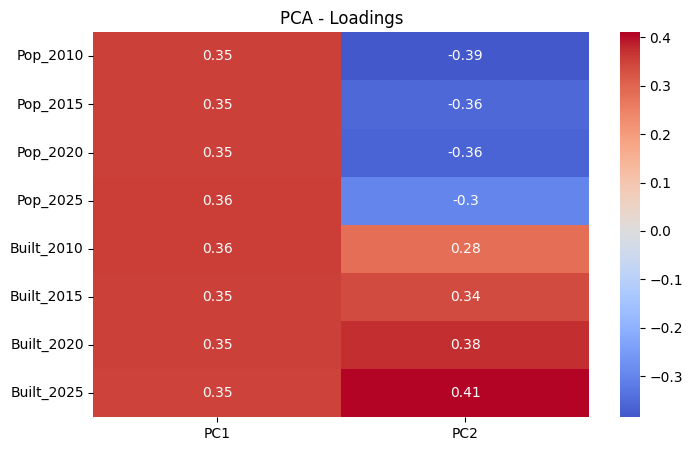

In [10]:

loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[
        f"PC{i+1}"
        for i in range(len(features))
    ]
)

print("Contributia caracteristicilor la componentele PCA:")
display(loadings[["PC1", "PC2"]].round(3))

plt.figure(figsize=(8, 5))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("PCA - Loadings")
plt.show()


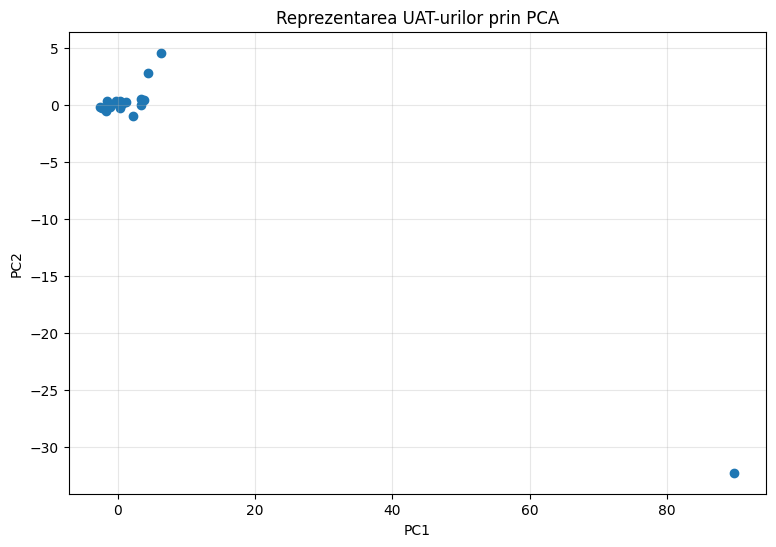

In [11]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X_test_pca[:, 0],
    X_test_pca[:, 1]
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Reprezentarea UAT-urilor prin PCA")
plt.grid(alpha=0.3)

plt.show()


In [12]:

from sklearn.manifold import trustworthiness
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

# Folosim componentele PCA alese
Z_test = X_test_pca[:, :k]

# 1. Indicator local: Trustworthiness
vecini = min(5, (len(X_test) - 1) // 2)

trust = trustworthiness(
    X_test_scaled,
    Z_test,
    n_neighbors=vecini
)

# 2. Indicator global: Stress
distante_initiale = pdist(X_test_scaled)
distante_pca = pdist(Z_test)

stress = np.sqrt(
    np.sum((distante_initiale - distante_pca) ** 2)
    / np.sum(distante_initiale ** 2)
)

# Corelatia distantelor
corelatie_distante = spearmanr(
    distante_initiale,
    distante_pca
).statistic

print("INDICATORI PCA")
print("Trustworthiness:", round(trust, 4))
print("Stress global:", round(stress, 4))
print("Corelatia distantelor:", round(corelatie_distante, 4))


INDICATORI PCA
Trustworthiness: 0.989
Stress global: 0.0646
Corelatia distantelor: 0.9799


In [13]:

from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.decomposition import PCA

# Selectam doar date istorice
predictori = [
    "Pop_2010",
    "Pop_2015",
    "Pop_2020",
    "Built_2010",
    "Built_2015",
    "Built_2020"
]

X_pred = df_valid[predictori]
y = df_valid["Pop_2025"]

# Folosim acelasi split
X_pred_train = X_pred.iloc[train_idx]
X_pred_test = X_pred.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Standardizare
scaler_pred = StandardScaler()

X_pred_train_scaled = scaler_pred.fit_transform(
    X_pred_train
)

X_pred_test_scaled = scaler_pred.transform(
    X_pred_test
)

# PCA cu doua componente
pca_pred = PCA(n_components=2)

Z_train = pca_pred.fit_transform(
    X_pred_train_scaled
)

Z_test_pred = pca_pred.transform(
    X_pred_test_scaled
)

# Model de predictie
model = KNeighborsRegressor(n_neighbors=5)

model.fit(Z_train, y_train)

y_pred = model.predict(Z_test_pred)

# Evaluare
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("EVALUARE DOWNSTREAM")
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))


EVALUARE DOWNSTREAM
RMSE: 41233.3
MAE: 9729.87


In [14]:

# Salvam indicatorii PCA
rezultate = pd.DataFrame({
    "Indicator": [
        "Numar UAT-uri",
        "Numar caracteristici",
        "Componente PCA",
        "Varianta explicata (%)",
        "Trustworthiness",
        "Stress global",
        "Corelatia distantelor",
        "RMSE predictie populatie",
        "MAE predictie populatie"
    ],
    "Valoare": [
        len(X),
        len(features),
        k,
        round(varianta_cumulata[k-1] * 100, 2),
        round(trust, 4),
        round(stress, 4),
        round(corelatie_distante, 4),
        round(rmse, 2),
        round(mae, 2)
    ]
})

display(rezultate)

rezultate.to_csv(
    "Rezultate_PCA_CP2.csv",
    index=False
)

loadings.to_csv("Loadings_PCA_CP2.csv")

print("Toate rezultatele au fost salvate.")


,Indicator,Valoare
0,Numar UAT-uri,104.0000
1,Numar caracteristici,8.0000
2,Componente PCA,1.0000
3,Varianta explicata (%),95.5600
4,Trustworthiness,0.9890
5,Stress global,0.0646
6,Corelatia distantelor,0.9799
7,RMSE predictie populatie,41233.3000
8,MAE predictie populatie,9729.8700


Toate rezultatele au fost salvate.
